# Arroyo Capital: inversión y portafolio en la industria del cine

**Proyecto final de Programación Analítica II**  
**Estudiante:** Vicente Alvarez  
**Universidad de Montevideo**

El objetivo es analizar la relación entre riesgo y retorno de distintos tipos de películas y construir una tesis de inversión para distribuir USD 500 millones.

## Etapa 1. Análisis exploratorio y correcciones de calidad

### 1.1 Carga inicial de los datos

Primero importamos las herramientas necesarias y definimos la ubicación de los archivos. Usamos rutas relativas para que el notebook funcione en otra computadora al clonar el repositorio.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px

# Esta ruta funciona tanto si Jupyter inicia en la raíz como en notebooks/.
RAIZ_PROYECTO = Path.cwd()
if RAIZ_PROYECTO.name == "notebooks":
    RAIZ_PROYECTO = RAIZ_PROYECTO.parent

RUTA_PELICULAS = RAIZ_PROYECTO / "datos" / "peliculas.csv"
RUTA_IPC = RAIZ_PROYECTO / "datos" / "ipc_eeuu.csv"

print(f"Películas: {RUTA_PELICULAS}")
print(f"IPC: {RUTA_IPC}")

Películas: C:\Users\Santi\Documents\Codex\programacion-analitica-2-portafolio-cine-alvarez\datos\peliculas.csv
IPC: C:\Users\Santi\Documents\Codex\programacion-analitica-2-portafolio-cine-alvarez\datos\ipc_eeuu.csv


Declaramos los tipos al cargar los archivos. Las variables de texto usan el tipo `string`, los enteros usan `Int64` y las variables continuas usan `Float64`. Estos tipos admiten valores faltantes, algo importante porque la consigna advierte que la base no está auditada. La fecha se convierte por separado con `errors="coerce"`, de modo que un valor inválido se transforma en faltante en vez de detener todo el notebook.

In [2]:
tipos_peliculas = {
    "id_pelicula": "Int64",
    "titulo": "string",
    "anio_estreno": "Int64",
    "fecha_estreno": "string",
    "genero": "string",
    "clasificacion": "string",
    "pais_origen": "string",
    "es_secuela": "string",
    "director": "string",
    "guionista": "string",
    "protagonista": "string",
    "productora": "string",
    "duracion_minutos": "Float64",
    "puntaje_imdb": "Float64",
    "cantidad_votos": "Float64",
    "presupuesto_usd": "Float64",
    "recaudacion_mundial_usd": "Float64",
}

peliculas = pd.read_csv(RUTA_PELICULAS, dtype=tipos_peliculas)
peliculas["fecha_estreno"] = pd.to_datetime(
    peliculas["fecha_estreno"], errors="coerce"
)

ipc = pd.read_csv(
    RUTA_IPC,
    dtype={"anio": "Int64", "ipc_eeuu": "Float64"},
)

Verificamos que ambos archivos se hayan cargado mostrando sus dimensiones, las primeras filas y los tipos resultantes. En esta instancia solo observamos: todavía no corregimos ni eliminamos datos.

In [3]:
print(f"peliculas.csv: {peliculas.shape[0]:,} filas y {peliculas.shape[1]} columnas")
print(f"ipc_eeuu.csv: {ipc.shape[0]:,} filas y {ipc.shape[1]} columnas")

display(peliculas.head())
display(ipc.head())

peliculas.csv: 7,740 filas y 17 columnas
ipc_eeuu.csv: 41 filas y 2 columnas


,id_pelicula,titulo,anio_estreno,fecha_estreno,genero,clasificacion,pais_origen,es_secuela,director,guionista,protagonista,productora,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd
0,15834,Hatchet II,2010,2010-07-01,Acción,Mayores de 17,Estados Unidos,Si,Adam Green,Adam Green,Danielle Harris,ArieScope Pictures,85.0,5.5,13000.0,800000.0,156190.0
1,10992,Shanghai Surprise,1986,1986-08-29,Aventura,Mayores de 13,UK,No,Jim Goddard,John Kohn,Sean Penn,HandMade Films,97.0,3.2,5000.0,17000000.0,2315683.0
2,15201,Mr. Magorium's Wonder Emporium,2007,2007-11-16,Comedia,Apta todo publico,Estados Unidos,No,Zach Helm,Zach Helm,Natalie Portman,Mandate Pictures,93.0,6.2,44000.0,65000000.0,69474661.0
3,13042,Celtic Pride,1996,1996-04-19,Comedia,Mayores de 13,Estados Unidos,No,Tom DeCerchio,Judd Apatow,Damon Wayans,Caravan Pictures,91.0,5.3,9600.0,<NA>,9255027.0
4,11961,Kafka,1991,1991-11-15,Drama,Mayores de 13,Francia,No,Steven Soderbergh,Lem Dobbs,Jeremy Irons,Baltimore Pictures,98.0,6.9,9600.0,11000000.0,1059071.0


,anio,ipc_eeuu
0,1980,82.4
1,1981,90.9
2,1982,96.5
3,1983,99.6
4,1984,103.9


In [4]:
print("Tipos de peliculas.csv:")
display(peliculas.dtypes.to_frame("tipo"))

print("Tipos de ipc_eeuu.csv:")
display(ipc.dtypes.to_frame("tipo"))

Tipos de peliculas.csv:


,tipo
id_pelicula,Int64
titulo,string
anio_estreno,Int64
fecha_estreno,datetime64[us]
genero,string
clasificacion,string
pais_origen,string
es_secuela,string
director,string
guionista,string


Tipos de ipc_eeuu.csv:


,tipo
anio,Int64
ipc_eeuu,Float64


**Conclusión de la carga:** los archivos quedaron disponibles para el análisis. `peliculas.csv` contiene 7.740 registros y 17 variables, mientras que `ipc_eeuu.csv` contiene 41 años y 2 variables. La carga conserva los faltantes y convierte las fechas inválidas en valores ausentes para auditarlas en los siguientes puntos.

### 1.2 Estructura y descripción general

En este punto resumimos la estructura de la base. Separamos las variables categóricas de las numéricas porque requieren medidas diferentes: en las primeras contamos categorías distintas y en las segundas observamos cantidad, promedio, dispersión, mínimos, cuartiles y máximos.

In [5]:
resumen_estructura = pd.DataFrame({
    "archivo": ["peliculas.csv", "ipc_eeuu.csv"],
    "filas": [peliculas.shape[0], ipc.shape[0]],
    "columnas": [peliculas.shape[1], ipc.shape[1]],
})
resumen_estructura

,archivo,filas,columnas
0,peliculas.csv,7740,17
1,ipc_eeuu.csv,41,2


In [6]:
columnas_categoricas = peliculas.select_dtypes(include="string").columns

categorias_por_variable = (
    peliculas[columnas_categoricas]
    .nunique(dropna=True)
    .sort_values()
    .rename("cantidad_categorias")
    .to_frame()
)
categorias_por_variable

,cantidad_categorias
es_secuela,2
clasificacion,10
genero,25
pais_origen,64
productora,2744
protagonista,2814
director,2949
guionista,4535
titulo,7512


In [7]:
columnas_numericas = peliculas.select_dtypes(include="number").columns

descripcion_numericas = (
    peliculas[columnas_numericas]
    .describe()
    .T
    .round(2)
)
descripcion_numericas

,count,mean,std,min,25%,50%,75%,max
id_pelicula,7740.0,13971.02,3920.34,10001.0,11921.75,13840.5,15759.25,90014.0
anio_estreno,7740.0,2000.4,11.15,1980.0,1991.0,2000.0,2010.0,2020.0
duracion_minutos,7736.0,108.83,44.86,0.0,95.0,104.0,116.0,999.0
puntaje_imdb,7737.0,6.37,1.03,0.0,5.8,6.5,7.1,9.3
cantidad_votos,7737.0,88122.35,163333.63,7.0,9100.0,33000.0,93000.0,2400000.0
presupuesto_usd,5551.0,35000792.4,41215579.81,-1.0,10000000.0,20000000.0,43000000.0,356000000.0
recaudacion_mundial_usd,7549.0,78600686.19,168497298.56,-622674139.0,4515258.0,20240502.0,76019048.0,2847246203.0


In [8]:
descripcion_ipc = ipc.describe().T.round(2)
descripcion_ipc

,count,mean,std,min,25%,50%,75%,max
anio,41.0,2000.0,11.98,1980.0,1990.0,2000.0,2010.0,2020.0
ipc_eeuu,41.0,173.46,52.66,82.4,130.7,172.2,218.1,258.8


**Conclusiones iniciales:**

- La base de películas tiene 7.740 filas y 17 columnas. La tabla del IPC cubre 41 años, desde 1980 hasta 2020.
- `clasificacion` presenta 10 categorías, aunque la documentación describe solo 6, y `genero` presenta 25. Esto anticipa categorías escritas de distintas maneras que deberán normalizarse.
- En votos, presupuesto y recaudación, el promedio es bastante mayor que la mediana. Esto indica distribuciones asimétricas, donde unas pocas películas muy grandes empujan el promedio hacia arriba.
- Aparecen mínimos o máximos imposibles: duración 0 y 999 minutos, puntaje IMDb 0, presupuesto -1 y recaudación negativa. Por ahora no se corrigen; quedan identificados para la auditoría de calidad.
- El presupuesto tiene menos observaciones válidas que las demás variables monetarias. El tratamiento de esos faltantes se decidirá más adelante después de estudiar si siguen algún patrón.

### 1.3 Duplicados exactos y películas repetidas

Una fila exactamente duplicada repite todos los valores y puede eliminarse sin perder información. En cambio, una película repetida con datos distintos representa un conflicto que debe investigarse antes de decidir qué registro conservar.

In [9]:
duplicados_exactos_extra = peliculas.duplicated().sum()
filas_en_duplicados_exactos = peliculas.duplicated(keep=False).sum()
porcentaje_duplicados_exactos = duplicados_exactos_extra / len(peliculas) * 100

resumen_duplicados = pd.DataFrame({
    "medida": [
        "copias exactas adicionales",
        "filas involucradas en duplicados exactos",
        "porcentaje de la base a eliminar",
    ],
    "valor": [
        duplicados_exactos_extra,
        filas_en_duplicados_exactos,
        round(porcentaje_duplicados_exactos, 2),
    ],
})
resumen_duplicados

,medida,valor
0,copias exactas adicionales,58.00
1,filas involucradas en duplicados exactos,116.00
2,porcentaje de la base a eliminar,0.75


In [10]:
ejemplos_duplicados_exactos = (
    peliculas[peliculas.duplicated(keep=False)]
    .sort_values(["id_pelicula", "titulo"])
    .head(10)
)
ejemplos_duplicados_exactos

,id_pelicula,titulo,anio_estreno,fecha_estreno,genero,clasificacion,pais_origen,es_secuela,director,guionista,protagonista,productora,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd
2780,10199,Scream,1981,1981-01-01,Terror,Mayores de 17,Estados Unidos,No,Byron Quisenberry,Byron Quisenberry,Pepper Martin,Calendar International Pictures,82.0,2.9,674.0,<NA>,<NA>
5907,10199,Scream,1981,1981-01-01,Terror,Mayores de 17,Estados Unidos,No,Byron Quisenberry,Byron Quisenberry,Pepper Martin,Calendar International Pictures,82.0,2.9,674.0,<NA>,<NA>
4905,10296,The Soldier,1982,1982-08-27,Acción,Mayores de 17,Estados Unidos,No,James Glickenhaus,James Glickenhaus,Ken Wahl,James Glickenhaus,96.0,5.3,1100.0,4000000.0,6328816.0
5448,10296,The Soldier,1982,1982-08-27,Acción,Mayores de 17,Estados Unidos,No,James Glickenhaus,James Glickenhaus,Ken Wahl,James Glickenhaus,96.0,5.3,1100.0,4000000.0,6328816.0
6992,10417,Escape from the Bronx,1983,1985-01-18,Acción,MAYORES DE 17,Italia,No,Enzo G. Castellari,Tito Carpi,Mark Gregory,FULVIA FILM,89.0,4.6,2300.0,<NA>,<NA>
7575,10417,Escape from the Bronx,1983,1985-01-18,Acción,MAYORES DE 17,Italia,No,Enzo G. Castellari,Tito Carpi,Mark Gregory,FULVIA FILM,89.0,4.6,2300.0,<NA>,<NA>
134,10499,Conan the Destroyer,1984,NaT,ACCION,Supervision parental,Estados Unidos,No,Richard Fleischer,Robert E. Howard,Arnold Schwarzenegger,Dino De Laurentiis Company,103.0,5.9,77000.0,18000000.0,31042035.0
6801,10499,Conan the Destroyer,1984,NaT,ACCION,Supervision parental,Estados Unidos,No,Richard Fleischer,Robert E. Howard,Arnold Schwarzenegger,Dino De Laurentiis Company,103.0,5.9,77000.0,18000000.0,31042035.0
4833,10645,The Goonies,1985,1985-06-07,Aventura,Supervisión parental,EE.UU.,No,Richard Donner,Chris Columbus,Sean Astin,Warner Bros.,114.0,7.8,252000.0,19000000.0,63980721.0
5321,10645,The Goonies,1985,1985-06-07,Aventura,Supervisión parental,EE.UU.,No,Richard Donner,Chris Columbus,Sean Astin,Warner Bros.,114.0,7.8,252000.0,19000000.0,63980721.0


Para buscar películas repetidas con datos distintos, primero quitamos temporalmente las copias exactas. Luego agrupamos por `titulo` y `anio_estreno`, una combinación razonable para identificar la misma película sin depender del identificador.

In [11]:
peliculas_sin_copias_exactas = peliculas.drop_duplicates()

mascara_repetidas_distintas = peliculas_sin_copias_exactas.duplicated(
    subset=["titulo", "anio_estreno"], keep=False
)
peliculas_repetidas_distintas = (
    peliculas_sin_copias_exactas[mascara_repetidas_distintas]
    .sort_values(["titulo", "anio_estreno", "id_pelicula"])
)

cantidad_grupos_repetidos = peliculas_repetidas_distintas.groupby(
    ["titulo", "anio_estreno"]
).ngroups

print(f"Películas repetidas con datos distintos: {cantidad_grupos_repetidos} pares")
print(f"Filas involucradas: {len(peliculas_repetidas_distintas)}")

Películas repetidas con datos distintos: 14 pares
Filas involucradas: 28


In [12]:
columnas_comparacion = [
    "id_pelicula",
    "titulo",
    "anio_estreno",
    "presupuesto_usd",
    "recaudacion_mundial_usd",
]
peliculas_repetidas_distintas[columnas_comparacion]

,id_pelicula,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd
1970,12898,Bio-Dome,1996,15000000.0,13427615.0
2653,90001,Bio-Dome,1996,19697118.0,13427615.0
2212,13101,Breakdown,1997,36000000.0,50159144.0
1747,90004,Breakdown,1997,31901667.0,50159144.0
5906,16378,Cloudy with a Chance of Meatballs 2,2013,78000000.0,274325949.0
3074,90008,Cloudy with a Chance of Meatballs 2,2013,93580153.0,274325949.0
6101,13883,Enemy at the Gates,2001,68000000.0,96976270.0
5510,90011,Enemy at the Gates,2001,43107007.0,96976270.0
5343,12897,Executive Decision,1996,55000000.0,121969216.0
6287,90002,Executive Decision,1996,59619028.0,121969216.0


**Conclusión sobre duplicados:** encontramos 58 copias exactas adicionales, equivalentes al 0,75 % de la base. También aparecen 14 pares de películas con el mismo título y año, pero con identificadores y presupuestos diferentes. En todos esos pares, uno de los identificadores comienza con 90000 y la recaudación coincide, mientras que cambia el presupuesto. Esto sugiere registros artificiales o alterados. Antes de modificar la base, dejamos documentada la decisión propuesta: eliminar las 58 copias exactas y, en los 14 pares conflictivos, conservar el registro con el identificador habitual y descartar el registro 90000. El efecto total sería retirar 72 filas, aproximadamente el 0,93 % de la base.

#### Corrección aplicada

Creamos `peliculas_limpias` para continuar el análisis sin alterar el DataFrame original. Primero retiramos las copias exactas y luego quitamos únicamente los 14 registros conflictivos cuyo identificador comienza con 90000.

In [13]:
filas_antes = len(peliculas)

# 1. Eliminamos solamente las copias adicionales de filas idénticas.
peliculas_limpias = peliculas.drop_duplicates().copy()

# 2. Identificamos los registros artificiales dentro de los pares conflictivos.
ids_conflictivos_90000 = peliculas_repetidas_distintas.loc[
    peliculas_repetidas_distintas["id_pelicula"] >= 90000,
    "id_pelicula",
].tolist()

peliculas_limpias = peliculas_limpias[
    ~peliculas_limpias["id_pelicula"].isin(ids_conflictivos_90000)
].copy()

filas_despues = len(peliculas_limpias)
filas_eliminadas = filas_antes - filas_despues
porcentaje_eliminado = filas_eliminadas / filas_antes * 100

In [14]:
control_correccion_duplicados = pd.DataFrame({
    "medida": [
        "filas antes",
        "copias exactas eliminadas",
        "registros 90000 eliminados",
        "filas después",
        "porcentaje total eliminado",
    ],
    "valor": [
        filas_antes,
        duplicados_exactos_extra,
        len(ids_conflictivos_90000),
        filas_despues,
        round(porcentaje_eliminado, 2),
    ],
})
control_correccion_duplicados

,medida,valor
0,filas antes,7740.00
1,copias exactas eliminadas,58.00
2,registros 90000 eliminados,14.00
3,filas después,7668.00
4,porcentaje total eliminado,0.93


In [15]:
print("Duplicados exactos restantes:", peliculas_limpias.duplicated().sum())
print("Identificadores conflictivos restantes:",
      peliculas_limpias["id_pelicula"].isin(ids_conflictivos_90000).sum())

Duplicados exactos restantes: 0
Identificadores conflictivos restantes: 0


**Resultado de la corrección:** la base de trabajo pasa de 7.740 a 7.668 filas. Se eliminaron 72 registros, equivalentes al 0,93 % del total. El CSV original y el DataFrame `peliculas` permanecen sin cambios, por lo que la transformación es reproducible y auditable. Desde este punto, los análisis siguientes utilizarán `peliculas_limpias`.

### 1.4 Valores faltantes

Cuantificamos los faltantes sobre `peliculas_limpias`. Reportamos tanto la cantidad como el porcentaje porque una misma cantidad puede tener distinta importancia según el tamaño de la base. En esta etapa no imputamos ni eliminamos datos.

In [16]:
resumen_faltantes = pd.DataFrame({
    "cantidad_faltantes": peliculas_limpias.isna().sum(),
    "porcentaje_faltantes": (peliculas_limpias.isna().mean() * 100).round(2),
})

resumen_faltantes = resumen_faltantes.sort_values(
    "cantidad_faltantes", ascending=False
)
resumen_faltantes

,cantidad_faltantes,porcentaje_faltantes
presupuesto_usd,2171,28.31
fecha_estreno,1167,15.22
recaudacion_mundial_usd,189,2.46
clasificacion,77,1.00
productora,15,0.20
duracion_minutos,4,0.05
puntaje_imdb,3,0.04
pais_origen,3,0.04
cantidad_votos,3,0.04
guionista,3,0.04


In [17]:
filas_con_algun_faltante = peliculas_limpias.isna().any(axis=1).sum()
porcentaje_filas_con_faltantes = (
    filas_con_algun_faltante / len(peliculas_limpias) * 100
)

print(f"Filas con al menos un faltante: {filas_con_algun_faltante:,}")
print(f"Porcentaje de filas afectadas: {porcentaje_filas_con_faltantes:.2f}%")

Filas con al menos un faltante: 3,074
Porcentaje de filas afectadas: 40.09%


El siguiente filtro muestra ejemplos de filas afectadas. Incluimos las variables principales para observar que los faltantes no siempre aparecen en las mismas columnas.

In [18]:
columnas_para_ejemplos = [
    "id_pelicula",
    "titulo",
    "anio_estreno",
    "fecha_estreno",
    "clasificacion",
    "duracion_minutos",
    "puntaje_imdb",
    "presupuesto_usd",
    "recaudacion_mundial_usd",
]

ejemplos_filas_con_faltantes = peliculas_limpias.loc[
    peliculas_limpias.isna().any(axis=1), columnas_para_ejemplos
].head(10)

ejemplos_filas_con_faltantes

,id_pelicula,titulo,anio_estreno,fecha_estreno,clasificacion,duracion_minutos,puntaje_imdb,presupuesto_usd,recaudacion_mundial_usd
3,13042,Celtic Pride,1996,1996-04-19,Mayores de 13,91.0,5.3,<NA>,9255027.0
5,11435,"Distant Voices, Still Lives",1988,NaT,Mayores de 13,84.0,7.4,<NA>,771745.0
7,10739,The Holcroft Covenant,1985,1985-10-18,Mayores de 17,112.0,5.7,<NA>,393825.0
8,12429,Silent Tongue,1993,NaT,Mayores de 13,102.0,5.3,<NA>,61274.0
10,15664,The American,2010,NaT,Mayores de 17,105.0,6.3,20000000.0,67876281.0
11,11791,An Angel at My Table,1990,1990-09-20,MAYORES DE 17,158.0,7.5,<NA>,1055995.0
12,11681,Nikita,1990,1990-07-01,Mayores de 17,117.0,7.3,<NA>,5017971.0
13,16780,Into the Forest,2015,2016-07-29,Mayores de 17,101.0,5.8,<NA>,92166.0
15,14557,District B13,2004,2006-06-02,Mayores de 17,84.0,7.1,<NA>,11169386.0
17,10240,Six Pack,1982,1982-07-16,Supervision parental,108.0,5.9,<NA>,20225989.0


**Conclusiones sobre faltantes:** el presupuesto es la variable más afectada, con 2.171 valores ausentes (28,31 %), por lo que eliminar todas esas filas sin estudiarlas podría sesgar el análisis. La fecha de estreno tiene 1.167 faltantes (15,22 %) y la recaudación mundial 189 (2,46 %). En total, 3.074 películas (40,09 %) tienen al menos un dato faltante, aunque muchas conservan la información necesaria para otros análisis. Por este motivo no aplicamos una eliminación general. El tratamiento del presupuesto se decidirá después de comparar sus faltantes por década, país y género, tal como exige la consigna.

### 1.5 Valores imposibles y centinelas

Buscamos valores que contradicen la definición de cada variable. También distinguimos un error evidente de un valor extremo posible: por ejemplo, una película puede durar más de 300 minutos, pero no puede durar 0 minutos ni tener una duración de 999 usada como centinela.

In [19]:
condiciones_imposibles = {
    "año fuera de 1980-2020": ~peliculas_limpias["anio_estreno"].between(1980, 2020),
    "duración igual a 0": peliculas_limpias["duracion_minutos"] == 0,
    "duración centinela 999": peliculas_limpias["duracion_minutos"] == 999,
    "IMDb fuera de 1-10": (
        ~peliculas_limpias["puntaje_imdb"].between(1, 10)
        & peliculas_limpias["puntaje_imdb"].notna()
    ),
    "votos negativos": peliculas_limpias["cantidad_votos"] < 0,
    "presupuesto menor o igual a 0": peliculas_limpias["presupuesto_usd"] <= 0,
    "recaudación negativa": peliculas_limpias["recaudacion_mundial_usd"] < 0,
}

resumen_valores_imposibles = pd.DataFrame({
    "problema": condiciones_imposibles.keys(),
    "filas_afectadas": [mascara.sum() for mascara in condiciones_imposibles.values()],
})
resumen_valores_imposibles["porcentaje_base"] = (
    resumen_valores_imposibles["filas_afectadas"]
    / len(peliculas_limpias)
    * 100
).round(2)
resumen_valores_imposibles

,problema,filas_afectadas,porcentaje_base
0,año fuera de 1980-2020,0,0.00
1,duración igual a 0,18,0.23
2,duración centinela 999,16,0.21
3,IMDb fuera de 1-10,22,0.29
4,votos negativos,0,0.00
5,presupuesto menor o igual a 0,48,0.63
6,recaudación negativa,11,0.14


In [20]:
columnas_revision = [
    "id_pelicula",
    "titulo",
    "anio_estreno",
    "duracion_minutos",
    "puntaje_imdb",
    "presupuesto_usd",
    "recaudacion_mundial_usd",
]

mascara_revision = pd.concat(condiciones_imposibles, axis=1).any(axis=1)
ejemplos_valores_imposibles = peliculas_limpias.loc[
    mascara_revision, columnas_revision
].head(20)
ejemplos_valores_imposibles

,id_pelicula,titulo,anio_estreno,duracion_minutos,puntaje_imdb,presupuesto_usd,recaudacion_mundial_usd
50,17258,Ant-Man and the Wasp,2018,118.0,7.0,162000000.0,-622674139.0
60,10819,Bliss,1985,999.0,6.9,<NA>,<NA>
117,16808,Rock the Kasbah,2015,106.0,5.5,-1.0,3394174.0
249,14789,Hustle & Flow,2005,116.0,7.3,0.0,23563727.0
305,16426,The Past,2013,130.0,0.0,11000000.0,12673462.0
356,15751,Dear John,2010,108.0,6.3,0.0,114984666.0
373,12914,Beavis and Butt-Head Do America,1996,81.0,6.8,-1.0,63118386.0
377,14167,Rollerball,2002,98.0,0.0,70000000.0,25852764.0
384,12092,Lethal Weapon 3,1992,118.0,6.7,-1.0,321731527.0
524,11337,Monkey Shines,1988,113.0,6.2,-1.0,5344577.0


In [21]:
print("Valores problemáticos de duración:")
display(
    peliculas_limpias.loc[
        peliculas_limpias["duracion_minutos"].isin([0, 999]),
        "duracion_minutos",
    ].value_counts().rename("cantidad").to_frame()
)

print("Valores no positivos de presupuesto:")
display(
    peliculas_limpias.loc[
        peliculas_limpias["presupuesto_usd"] <= 0,
        "presupuesto_usd",
    ].value_counts().rename("cantidad").to_frame()
)

Valores problemáticos de duración:


,cantidad
duracion_minutos,
0.0,18
999.0,16


Valores no positivos de presupuesto:


,cantidad
presupuesto_usd,
0.0,26
-1.0,22


**Conclusiones y corrección propuesta:**

- Hay 18 duraciones iguales a 0 y 16 iguales a 999. Ambos valores funcionan como faltantes disfrazados y deberían convertirse en `NaN`. Las duraciones reales de 357 y 366 minutos se conservan porque pertenecen a películas excepcionalmente largas, pero posibles.
- Hay 22 puntajes IMDb iguales a 0. Como la escala válida comienza en 1, deberían convertirse en `NaN`.
- Hay 48 presupuestos no positivos: 26 ceros y 22 valores `-1`. No representan presupuestos reales y deberían convertirse en `NaN`.
- Hay 11 recaudaciones negativas. La recaudación bruta no puede ser negativa y las magnitudes coinciden con valores plausibles escritos con signo incorrecto, por lo que se propone corregirlas tomando su valor absoluto.
- No encontramos años fuera de 1980-2020 ni cantidades de votos negativas.

Todavía no aplicamos estas correcciones: primero dejamos documentada la regla para aprobarla antes de modificar la base de trabajo.

#### Corrección aplicada

Aplicamos las reglas aprobadas sobre `peliculas_limpias`. Los centinelas se convierten en faltantes reales para que Pandas no los incluya en promedios o medianas. Las recaudaciones negativas se corrigen con valor absoluto, ya que el problema es únicamente el signo.

In [22]:
mascara_duracion_invalida = peliculas_limpias["duracion_minutos"].isin([0, 999])
mascara_imdb_invalido = peliculas_limpias["puntaje_imdb"] == 0
mascara_presupuesto_invalido = peliculas_limpias["presupuesto_usd"] <= 0
mascara_recaudacion_negativa = peliculas_limpias["recaudacion_mundial_usd"] < 0

mascara_alguna_correccion = (
    mascara_duracion_invalida
    | mascara_imdb_invalido
    | mascara_presupuesto_invalido
    | mascara_recaudacion_negativa
)

faltantes_antes_correccion = peliculas_limpias[[
    "duracion_minutos",
    "puntaje_imdb",
    "presupuesto_usd",
    "recaudacion_mundial_usd",
]].isna().sum()

In [23]:
peliculas_limpias.loc[mascara_duracion_invalida, "duracion_minutos"] = pd.NA
peliculas_limpias.loc[mascara_imdb_invalido, "puntaje_imdb"] = pd.NA
peliculas_limpias.loc[mascara_presupuesto_invalido, "presupuesto_usd"] = pd.NA
peliculas_limpias.loc[
    mascara_recaudacion_negativa, "recaudacion_mundial_usd"
] = peliculas_limpias.loc[
    mascara_recaudacion_negativa, "recaudacion_mundial_usd"
].abs()

In [24]:
faltantes_despues_correccion = peliculas_limpias[[
    "duracion_minutos",
    "puntaje_imdb",
    "presupuesto_usd",
    "recaudacion_mundial_usd",
]].isna().sum()

control_correcciones = pd.DataFrame({
    "faltantes_antes": faltantes_antes_correccion,
    "faltantes_despues": faltantes_despues_correccion,
    "nuevos_faltantes_identificados": (
        faltantes_despues_correccion - faltantes_antes_correccion
    ),
})
control_correcciones

,faltantes_antes,faltantes_despues,nuevos_faltantes_identificados
duracion_minutos,4,38,34
puntaje_imdb,3,25,22
presupuesto_usd,2171,2219,48
recaudacion_mundial_usd,189,189,0


In [25]:
filas_corregidas = mascara_alguna_correccion.sum()
porcentaje_filas_corregidas = filas_corregidas / len(peliculas_limpias) * 100

print(f"Filas afectadas por alguna corrección: {filas_corregidas}")
print(f"Porcentaje de la base afectado: {porcentaje_filas_corregidas:.2f}%")
print("La corrección de valores problemáticos quedó aplicada.")

Filas afectadas por alguna corrección: 115
Porcentaje de la base afectado: 1.50%
La corrección de valores problemáticos quedó aplicada.


**Resultado de la corrección:** se modificaron 115 filas, equivalentes al 1,50 % de la base limpia. Los faltantes de duración aumentan de 4 a 38, los de IMDb de 3 a 25 y los de presupuesto de 2.171 a 2.219. La recaudación conserva 189 faltantes porque sus 11 valores negativos fueron corregidos, no eliminados. Las comprobaciones confirman que ya no permanecen los centinelas tratados.

### 1.6 Presupuestos cargados en otra escala

Un presupuesto pequeño no es automáticamente un error: algunas películas de muy bajo costo lograron grandes recaudaciones. Para detectar problemas de escala cruzamos presupuesto y recaudación mediante un múltiplo provisional (`recaudación / presupuesto`). Este múltiplo se usa solo como control de calidad; las variables financieras definitivas se construirán más adelante.

In [26]:
peliculas_limpias["multiplo_recaudacion_presupuesto"] = (
    peliculas_limpias["recaudacion_mundial_usd"]
    / peliculas_limpias["presupuesto_usd"]
)

candidatas_otra_escala = peliculas_limpias.loc[
    (peliculas_limpias["presupuesto_usd"] < 100_000)
    & (peliculas_limpias["recaudacion_mundial_usd"] > 10_000_000)
    & (peliculas_limpias["multiplo_recaudacion_presupuesto"] > 500)
].copy()

columnas_escala = [
    "id_pelicula",
    "titulo",
    "anio_estreno",
    "presupuesto_usd",
    "recaudacion_mundial_usd",
    "multiplo_recaudacion_presupuesto",
]

candidatas_otra_escala[columnas_escala].sort_values(
    "multiplo_recaudacion_presupuesto", ascending=False
)

,id_pelicula,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd,multiplo_recaudacion_presupuesto
264,10853,Platoon,1986,6000.0,138545632.0,23090.938667
4439,13134,Bean,1997,18000.0,251212670.0,13956.259444
5927,15115,Paranormal Activity,2007,15000.0,193355800.0,12890.386667
1882,14782,"Good Night, and Good Luck.",2005,7000.0,54641191.0,7805.884429
3336,15266,Sex and the City,2008,65000.0,418765519.0,6442.546446
1648,13460,The Blair Witch Project,1999,60000.0,248639099.0,4143.984983
283,16412,21 & Over,2013,13000.0,48065672.0,3697.359385
3393,14058,The Bourne Identity,2002,60000.0,214034224.0,3567.237067
99,16320,Safe Haven,2013,28000.0,97594140.0,3485.505
2039,11093,Broadcast News,1987,20000.0,67331309.0,3366.56545


El filtro encuentra 29 casos. Sin embargo, dos corresponden a éxitos de muy bajo presupuesto ampliamente reconocibles en los propios datos: *Paranormal Activity* (USD 15.000) y *The Blair Witch Project* (USD 60.000). No deben corregirse solo por tener un retorno extraordinario. Excluimos esas dos películas y evaluamos si multiplicar los otros presupuestos por 1.000 produce valores coherentes.

In [27]:
excepciones_bajo_presupuesto_real = [
    "Paranormal Activity",
    "The Blair Witch Project",
]

errores_escala_presupuesto = candidatas_otra_escala.loc[
    ~candidatas_otra_escala["titulo"].isin(excepciones_bajo_presupuesto_real)
].copy()

errores_escala_presupuesto["presupuesto_propuesto_usd"] = (
    errores_escala_presupuesto["presupuesto_usd"] * 1_000
)
errores_escala_presupuesto["multiplo_corregido"] = (
    errores_escala_presupuesto["recaudacion_mundial_usd"]
    / errores_escala_presupuesto["presupuesto_propuesto_usd"]
)

errores_escala_presupuesto[[
    "titulo",
    "presupuesto_usd",
    "presupuesto_propuesto_usd",
    "multiplo_recaudacion_presupuesto",
    "multiplo_corregido",
]].sort_values("multiplo_recaudacion_presupuesto", ascending=False)

,titulo,presupuesto_usd,presupuesto_propuesto_usd,multiplo_recaudacion_presupuesto,multiplo_corregido
264,Platoon,6000.0,6000000.0,23090.938667,23.090939
4439,Bean,18000.0,18000000.0,13956.259444,13.956259
1882,"Good Night, and Good Luck.",7000.0,7000000.0,7805.884429,7.805884
3336,Sex and the City,65000.0,65000000.0,6442.546446,6.442546
283,21 & Over,13000.0,13000000.0,3697.359385,3.697359
3393,The Bourne Identity,60000.0,60000000.0,3567.237067,3.567237
99,Safe Haven,28000.0,28000000.0,3485.505,3.485505
2039,Broadcast News,20000.0,20000000.0,3366.56545,3.366565
4546,Powder,9500.0,9500000.0,3248.648,3.248648
2262,The Object of My Affection,15000.0,15000000.0,3127.059267,3.127059


In [28]:
print(f"Casos detectados por el filtro: {len(candidatas_otra_escala)}")
print(f"Producciones baratas que se conservan: {len(excepciones_bajo_presupuesto_real)}")
print(f"Errores de escala propuestos: {len(errores_escala_presupuesto)}")
print(
    "Porcentaje de la base afectado: "
    f"{len(errores_escala_presupuesto) / len(peliculas_limpias) * 100:.2f}%"
)

Casos detectados por el filtro: 29
Producciones baratas que se conservan: 2
Errores de escala propuestos: 27
Porcentaje de la base afectado: 0.35%


**Conclusión:** el cruce entre presupuesto y recaudación detectó 29 valores extremadamente improbables. Dos son producciones genuinamente baratas y se conservan sin cambios. En los 27 casos restantes, multiplicar el presupuesto por 1.000 produce montos de entre USD 6 millones y USD 93 millones y múltiplos de recaudación plausibles. La corrección afecta solo al 0,35 % de la base.

### Aplicación de la corrección de escala

Se multiplican por 1.000 únicamente los 27 presupuestos identificados. Las dos excepciones se mantienen porque sus presupuestos bajos son coherentes con producciones independientes conocidas. El archivo CSV original no se modifica: la corrección se realiza sobre `peliculas_limpias`.

In [29]:
indices_escala_incorrecta = errores_escala_presupuesto.index
presupuestos_antes = peliculas_limpias.loc[indices_escala_incorrecta, "presupuesto_usd"].copy()

peliculas_limpias.loc[indices_escala_incorrecta, "presupuesto_usd"] *= 1_000
peliculas_limpias["multiplo_recaudacion_presupuesto"] = (
    peliculas_limpias["recaudacion_mundial_usd"]
    / peliculas_limpias["presupuesto_usd"]
)

resumen_correccion_escala = peliculas_limpias.loc[indices_escala_incorrecta, [
    "titulo", "presupuesto_usd", "multiplo_recaudacion_presupuesto"
]].copy()
resumen_correccion_escala.insert(1, "presupuesto_antes_usd", presupuestos_antes)
resumen_correccion_escala.rename(columns={
    "presupuesto_usd": "presupuesto_corregido_usd",
    "multiplo_recaudacion_presupuesto": "multiplo_corregido",
}).sort_values("titulo")

,titulo,presupuesto_antes_usd,presupuesto_corregido_usd,multiplo_corregido
283,21 & Over,13000.0,13000000.0,3.697359
638,Basic,50000.0,50000000.0,0.855851
4439,Bean,18000.0,18000000.0,13.956259
2039,Broadcast News,20000.0,20000000.0,3.366565
1882,"Good Night, and Good Luck.",7000.0,7000000.0,7.805884
6748,LOL,11000.0,11000000.0,0.961695
5776,Man of the House,40000.0,40000000.0,0.539441
4473,Micki + Maude,15100.0,15100000.0,1.727209
264,Platoon,6000.0,6000000.0,23.090939
5873,Poltergeist II: the Other Side,19000.0,19000000.0,2.157719


In [30]:
cantidad_corregida = len(indices_escala_incorrecta)
porcentaje_corregido = cantidad_corregida / len(peliculas_limpias) * 100

print(f"Presupuestos corregidos: {cantidad_corregida}")
print(f"Porcentaje de la base modificado: {porcentaje_corregido:.2f}%")
print("Presupuesto corregido mínimo: " f"USD {peliculas_limpias.loc[indices_escala_incorrecta, 'presupuesto_usd'].min():,.0f}")
print("Presupuesto corregido máximo: " f"USD {peliculas_limpias.loc[indices_escala_incorrecta, 'presupuesto_usd'].max():,.0f}")
print("Las dos películas de bajo presupuesto real se conservaron sin cambios.")

Presupuestos corregidos: 27
Porcentaje de la base modificado: 0.35%
Presupuesto corregido mínimo: USD 6,000,000
Presupuesto corregido máximo: USD 93,000,000
Las dos películas de bajo presupuesto real se conservaron sin cambios.


**Decisión aplicada:** se corrigieron 27 presupuestos (0,35 % de las películas limpias). La intervención es puntual, reproducible y conserva los casos de bajo presupuesto real. A partir de este punto, los análisis posteriores utilizan los valores corregidos.

## 1.7 Normalización de variables categóricas

Se revisan `genero`, `clasificacion` y `pais_origen`. El objetivo es unir categorías que representan lo mismo pero aparecen con diferencias de mayúsculas, tildes, abreviaturas o espacios. No se eliminan películas ni se completan datos faltantes.

In [31]:
columnas_categoricas = ["genero", "clasificacion", "pais_origen"]
categorias_antes = peliculas_limpias[columnas_categoricas].nunique(dropna=True)
categorias_antes.to_frame("categorias_antes")

,categorias_antes
genero,25
clasificacion,10
pais_origen,64


In [32]:
valores_antes = peliculas_limpias[columnas_categoricas].copy()

# Primero se quitan espacios accidentales al inicio o al final.
for columna in columnas_categoricas:
    peliculas_limpias[columna] = peliculas_limpias[columna].str.strip()

mapa_generos = {
    "comedia": "Comedia",
    "ACCION": "Acción",
    "POLICIAL": "Policial",
    "Biografia": "Biografía",
    "Animacion": "Animación",
    "Ciencia Ficcion": "Ciencia ficción",
}

mapa_clasificaciones = {
    "MAYORES DE 17": "Mayores de 17",
    "Supervision parental": "Supervisión parental",
    "ATP": "Apta para todo público",
    "Apta todo publico": "Apta para todo público",
}

mapa_paises = {
    "EE.UU.": "Estados Unidos",
    "UK": "Reino Unido",
    "Canada": "Canadá",
    "Japon": "Japón",
    "Espania": "España",
    "Mexico": "México",
}

peliculas_limpias["genero"] = peliculas_limpias["genero"].replace(mapa_generos)
peliculas_limpias["clasificacion"] = peliculas_limpias["clasificacion"].replace(mapa_clasificaciones)
peliculas_limpias["pais_origen"] = peliculas_limpias["pais_origen"].replace(mapa_paises)

In [33]:
categorias_despues = peliculas_limpias[columnas_categoricas].nunique(dropna=True)
filas_modificadas = valores_antes.ne(peliculas_limpias[columnas_categoricas]).any(axis=1)
cantidad_filas_modificadas = int(filas_modificadas.sum())
porcentaje_filas_modificadas = cantidad_filas_modificadas / len(peliculas_limpias) * 100

resumen_categorias = pd.DataFrame({
    "categorias_antes": categorias_antes,
    "categorias_despues": categorias_despues,
    "reduccion": categorias_antes - categorias_despues,
})
display(resumen_categorias)
print(f"Filas con al menos una categoría normalizada: {cantidad_filas_modificadas:,}")
print(f"Porcentaje de la base afectado: {porcentaje_filas_modificadas:.2f}%")
print(f"Cantidad de filas antes y después: {len(valores_antes):,} / {len(peliculas_limpias):,}")

,categorias_antes,categorias_despues,reduccion
genero,25,18,7
clasificacion,10,6,4
pais_origen,64,58,6


Filas con al menos una categoría normalizada: 2,216
Porcentaje de la base afectado: 28.90%
Cantidad de filas antes y después: 7,668 / 7,668


In [34]:
print("La normalización no cambió la cantidad de filas:",
      len(valores_antes) == len(peliculas_limpias))

La normalización no cambió la cantidad de filas: True


**Conclusión:** se unificaron únicamente variantes equivalentes. Por ejemplo, `EE.UU.` se agrupó con `Estados Unidos`, `UK` con `Reino Unido`, y las diferencias de mayúsculas o tildes en géneros y clasificaciones dejaron de crear grupos artificiales. No se agruparon países históricos ni categorías con significados diferentes.

## 1.8 Cobertura temporal

Se analiza la cantidad de películas por año, la continuidad del período y la compatibilidad temporal entre la base cinematográfica y el IPC. También se revisa si `anio_estreno` coincide con el año extraído de `fecha_estreno`.

In [35]:
anio_minimo = int(peliculas_limpias["anio_estreno"].min())
anio_maximo = int(peliculas_limpias["anio_estreno"].max())
anios_esperados = set(range(anio_minimo, anio_maximo + 1))
anios_observados = set(peliculas_limpias["anio_estreno"].dropna().astype(int))
anios_sin_peliculas = sorted(anios_esperados - anios_observados)

ipc_anio_minimo = int(ipc["anio"].min())
ipc_anio_maximo = int(ipc["anio"].max())
anios_ipc = set(ipc["anio"].dropna().astype(int))
anios_peliculas_sin_ipc = sorted(anios_observados - anios_ipc)

print(f"Películas: {anio_minimo}-{anio_maximo} ({len(anios_observados)} años distintos)")
print(f"Años sin películas dentro del período: {anios_sin_peliculas or 'ninguno'}")
print(f"IPC: {ipc_anio_minimo}-{ipc_anio_maximo} ({len(anios_ipc)} años distintos)")
print(f"Años de películas sin IPC: {anios_peliculas_sin_ipc or 'ninguno'}")

Películas: 1980-2020 (41 años distintos)
Años sin películas dentro del período: ninguno
IPC: 1980-2020 (41 años distintos)
Años de películas sin IPC: ninguno


In [36]:
cobertura_por_anio = (
    peliculas_limpias.groupby("anio_estreno")
    .agg(
        cantidad_peliculas=("id_pelicula", "size"),
        fechas_faltantes=("fecha_estreno", lambda serie: serie.isna().sum()),
    )
    .reset_index()
)
cobertura_por_anio["porcentaje_fecha_faltante"] = (
    cobertura_por_anio["fechas_faltantes"]
    / cobertura_por_anio["cantidad_peliculas"] * 100
)
cobertura_por_anio

,anio_estreno,cantidad_peliculas,fechas_faltantes,porcentaje_fecha_faltante
0,1980,92,7,7.608696
1,1981,113,15,13.274336
2,1982,126,19,15.079365
3,1983,144,26,18.055556
4,1984,168,17,10.119048
5,1985,200,28,14.0
6,1986,200,33,16.5
7,1987,200,37,18.5
8,1988,200,30,15.0
9,1989,200,35,17.5


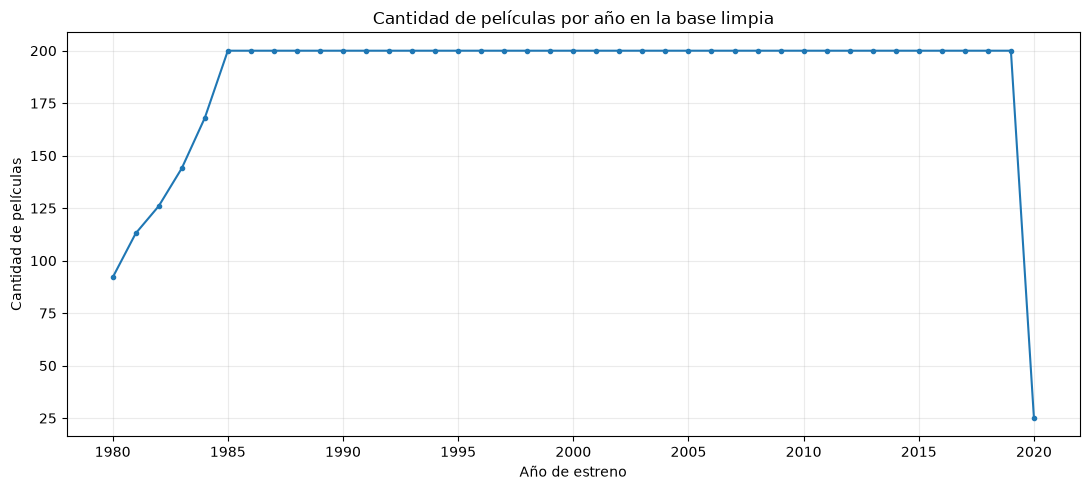

In [37]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(
    cobertura_por_anio["anio_estreno"],
    cobertura_por_anio["cantidad_peliculas"],
    marker="o",
    markersize=3,
)
ax.set_title("Cantidad de películas por año en la base limpia")
ax.set_xlabel("Año de estreno")
ax.set_ylabel("Cantidad de películas")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretación del gráfico:** desde 1985 hasta 2019 aparecen exactamente 200 películas por año. Esa regularidad indica que la base probablemente tiene un límite o una selección anual, por lo que este gráfico informa sobre la **cobertura del conjunto de datos**, no sobre la cantidad total de películas producidas por la industria. La caída de 2020 a 25 títulos confirma que ese año está incompleto y debe tratarse con cautela.

In [38]:
con_fecha = peliculas_limpias["fecha_estreno"].notna()
anio_fecha = peliculas_limpias.loc[con_fecha, "fecha_estreno"].dt.year
anio_declarado = peliculas_limpias.loc[con_fecha, "anio_estreno"].astype(int)
diferencias_anio_fecha = peliculas_limpias.loc[con_fecha & (
    peliculas_limpias["fecha_estreno"].dt.year
    != peliculas_limpias["anio_estreno"]
), ["titulo", "anio_estreno", "fecha_estreno"]]

print(f"Películas con fecha disponible: {con_fecha.sum():,}")
print(f"Diferencias entre año y fecha: {len(diferencias_anio_fecha):,}")
print(
    "Porcentaje sobre las fechas disponibles: "
    f"{len(diferencias_anio_fecha) / con_fecha.sum() * 100:.2f}%"
)
diferencias_anio_fecha.head(10)

Películas con fecha disponible: 6,501
Diferencias entre año y fecha: 1,096
Porcentaje sobre las fechas disponibles: 16.86%


,titulo,anio_estreno,fecha_estreno
13,Into the Forest,2015,2016-07-29
15,District B13,2004,2006-06-02
49,The Quiet American,2002,2003-03-07
54,Fireworks,1997,1998-03-20
60,Bliss,1985,1986-02-21
61,Chocolat,2000,2001-01-19
70,Welcome to the Dollhouse,1995,1996-05-24
72,A Very Long Engagement,2004,2005-01-14
74,"I, Tonya",2017,2018-01-19
75,Beautiful Creatures,2000,2001-01-19


**Criterio:** `anio_estreno` será la referencia temporal principal porque está completo y es suficiente para cruzar cada película con el IPC anual. `fecha_estreno` se conserva para posibles análisis más detallados, pero sus faltantes no justifican eliminar películas. Las diferencias puntuales entre ambas variables se informan y no se corrigen automáticamente, ya que pueden corresponder a estrenos en festivales, mercados o países distintos.

## 1.9 Análisis y tratamiento de presupuestos faltantes

El presupuesto es indispensable para calcular retornos, pero no conviene eliminar o imputar casos sin estudiar antes si los faltantes se concentran en determinados períodos o tipos de películas.

In [39]:
peliculas_limpias["tiene_presupuesto"] = peliculas_limpias["presupuesto_usd"].notna()
peliculas_limpias["decada"] = (
    peliculas_limpias["anio_estreno"] // 10 * 10
).astype("Int64")

cantidad_sin_presupuesto = int((~peliculas_limpias["tiene_presupuesto"]).sum())
porcentaje_sin_presupuesto = cantidad_sin_presupuesto / len(peliculas_limpias) * 100
print(f"Películas sin presupuesto: {cantidad_sin_presupuesto:,}")
print(f"Porcentaje de la base limpia: {porcentaje_sin_presupuesto:.2f}%")

Películas sin presupuesto: 2,219
Porcentaje de la base limpia: 28.94%


In [40]:
faltantes_por_decada = (
    peliculas_limpias.groupby("decada", dropna=False)
    .agg(
        peliculas=("id_pelicula", "size"),
        sin_presupuesto=("presupuesto_usd", lambda serie: serie.isna().sum()),
    )
)
faltantes_por_decada["porcentaje_sin_presupuesto"] = (
    faltantes_por_decada["sin_presupuesto"]
    / faltantes_por_decada["peliculas"] * 100
).round(2)
faltantes_por_decada

,peliculas,sin_presupuesto,porcentaje_sin_presupuesto
decada,,,
1980,1643,722,43.94
1990,2000,631,31.55
2000,2000,360,18.0
2010,2000,496,24.8
2020,25,10,40.0


In [41]:
faltantes_por_genero = (
    peliculas_limpias.groupby("genero", dropna=False)
    .agg(
        peliculas=("id_pelicula", "size"),
        sin_presupuesto=("presupuesto_usd", lambda serie: serie.isna().sum()),
    )
)
faltantes_por_genero["porcentaje_sin_presupuesto"] = (
    faltantes_por_genero["sin_presupuesto"]
    / faltantes_por_genero["peliculas"] * 100
).round(2)
faltantes_por_genero.sort_values("porcentaje_sin_presupuesto", ascending=False)

,peliculas,sin_presupuesto,porcentaje_sin_presupuesto
genero,,,
Musical,3,3,100.0
Deportiva,1,1,100.0
Familiar,11,7,63.64
Romance,10,5,50.0
Suspenso,16,7,43.75
Drama,1518,645,42.49
Comedia,2245,753,33.54
Western,3,1,33.33
Biografía,443,128,28.89


In [42]:
faltantes_por_pais = (
    peliculas_limpias.groupby("pais_origen", dropna=False)
    .agg(
        peliculas=("id_pelicula", "size"),
        sin_presupuesto=("presupuesto_usd", lambda serie: serie.isna().sum()),
    )
)
faltantes_por_pais["porcentaje_sin_presupuesto"] = (
    faltantes_por_pais["sin_presupuesto"]
    / faltantes_por_pais["peliculas"] * 100
).round(2)

# Se muestran países con al menos 20 películas para evitar porcentajes engañosos.
faltantes_por_pais.loc[faltantes_por_pais["peliculas"] >= 20].sort_values(
    "porcentaje_sin_presupuesto", ascending=False
)

,peliculas,sin_presupuesto,porcentaje_sin_presupuesto
pais_origen,,,
India,62,53,85.48
Suecia,25,20,80.0
Italia,61,42,68.85
Dinamarca,32,21,65.62
España,47,30,63.83
Corea del Sur,35,22,62.86
Francia,279,174,62.37
Japón,81,49,60.49
Australia,92,50,54.35


In [43]:
comparacion_presupuesto = (
    peliculas_limpias.groupby("tiene_presupuesto")
    .agg(
        peliculas=("id_pelicula", "size"),
        mediana_recaudacion=("recaudacion_mundial_usd", "median"),
        mediana_votos=("cantidad_votos", "median"),
        mediana_imdb=("puntaje_imdb", "median"),
    )
)
comparacion_presupuesto.index = ["Sin presupuesto", "Con presupuesto"]
comparacion_presupuesto

,peliculas,mediana_recaudacion,mediana_votos,mediana_imdb
Sin presupuesto,2219,4150418.5,8900.0,6.5
Con presupuesto,5449,36606743.0,51000.0,6.45


### Decisión de tratamiento

Los faltantes muestran un patrón concreto:

- En la década de 1980 falta el 43,94 % de los presupuestos, frente al 18,00 % en los años 2000.
- Entre los géneros numerosos, Drama presenta 42,49 % de faltantes, Comedia 33,54 % y Acción 17,01 %.
- En países con al menos 20 películas, la ausencia es especialmente alta en India (85,48 %), Suecia (80,00 %) e Italia (68,85 %), mientras que Estados Unidos presenta 20,75 %.
- Las películas sin presupuesto tienen una mediana de recaudación y de votos considerablemente menor, señal de que la disponibilidad también está relacionada con la visibilidad comercial.

No se imputarán los presupuestos faltantes. La proporción es demasiado grande para reemplazarla con una media o mediana sin introducir información artificial, y las diferencias entre segmentos indican que los faltantes no son completamente aleatorios. Las películas se conservarán para análisis que no requieran presupuesto, pero se excluirán explícitamente de los cálculos de retorno, recuperación de inversión y simulación del portafolio. En cada análisis se informará el tamaño de la muestra utilizada.

In [44]:
peliculas_financieras = peliculas_limpias.loc[
    peliculas_limpias["presupuesto_usd"].notna()
    & peliculas_limpias["recaudacion_mundial_usd"].notna()
].copy()

print(f"Base limpia completa: {len(peliculas_limpias):,} películas")
print(f"Muestra disponible para análisis financiero: {len(peliculas_financieras):,} películas")
print(
    "Cobertura de la muestra financiera: "
    f"{len(peliculas_financieras) / len(peliculas_limpias) * 100:.2f}%"
)

Base limpia completa: 7,668 películas
Muestra disponible para análisis financiero: 5,389 películas
Cobertura de la muestra financiera: 70.28%


## Etapa 2. Creación de variables financieras

En esta etapa se llevan el presupuesto y la recaudación a dólares de 2020 para poder comparar películas estrenadas en años diferentes. Después se calculan el retorno sobre la inversión y el indicador de recuperación establecido en la consigna.

## 2.1 Ajuste por inflación

Se utiliza 2020 como año base porque es el último año disponible en ambas bases. El factor de actualización es `IPC de 2020 / IPC del año de estreno`. Luego se multiplica cada monto nominal por ese factor.

In [45]:
anio_base = 2020
ipc_base = ipc.loc[ipc["anio"] == anio_base, "ipc_eeuu"].iloc[0]

print(f"Año base: {anio_base}")
print(f"IPC del año base: {ipc_base}")

Año base: 2020
IPC del año base: 258.8


In [46]:
filas_antes_cruce = len(peliculas_limpias)

peliculas_limpias = peliculas_limpias.merge(
    ipc, left_on="anio_estreno", right_on="anio", how="left"
)

print(f"Filas antes del cruce: {filas_antes_cruce:,}")
print(f"Filas después del cruce: {len(peliculas_limpias):,}")
print(f"Películas sin IPC asignado: {peliculas_limpias['ipc_eeuu'].isna().sum()}")

Filas antes del cruce: 7,668
Filas después del cruce: 7,668
Películas sin IPC asignado: 0


In [47]:
peliculas_limpias["factor_inflacion"] = ipc_base / peliculas_limpias["ipc_eeuu"]
peliculas_limpias["presupuesto_2020_usd"] = (
    peliculas_limpias["presupuesto_usd"] * peliculas_limpias["factor_inflacion"]
)
peliculas_limpias["recaudacion_2020_usd"] = (
    peliculas_limpias["recaudacion_mundial_usd"] * peliculas_limpias["factor_inflacion"]
)

peliculas_limpias[[
    "titulo", "anio_estreno", "factor_inflacion",
    "presupuesto_usd", "presupuesto_2020_usd",
    "recaudacion_mundial_usd", "recaudacion_2020_usd",
]].head()

,titulo,anio_estreno,factor_inflacion,presupuesto_usd,presupuesto_2020_usd,recaudacion_mundial_usd,recaudacion_2020_usd
0,Hatchet II,2010,1.186612,800000.0,949289.316827,156190.0,185336.872994
1,Shanghai Surprise,1986,2.361314,17000000.0,40142335.766423,2315683.0,5468054.383212
2,Mr. Magorium's Wonder Emporium,2007,1.248432,65000000.0,81148094.548963,69474661.0,86734405.532079
3,Celtic Pride,1996,1.649458,<NA>,<NA>,9255027.0,15265780.67304
4,Kafka,1991,1.900147,11000000.0,20901615.271659,1059071.0,2012390.417034


## 2.2 Retorno y recuperación de la inversión

El ROI se calcula como `(recaudación - presupuesto) / presupuesto`. Como la recaudación mundial no queda íntegramente en manos del productor, la consigna adopta un criterio más exigente para considerar recuperada la inversión: la recaudación debe superar 2,5 veces el presupuesto.

In [48]:
peliculas_limpias["roi"] = (
    peliculas_limpias["recaudacion_2020_usd"]
    - peliculas_limpias["presupuesto_2020_usd"]
) / peliculas_limpias["presupuesto_2020_usd"]

peliculas_limpias["multiplo_recaudacion"] = (
    peliculas_limpias["recaudacion_2020_usd"]
    / peliculas_limpias["presupuesto_2020_usd"]
)
peliculas_limpias["recupero_inversion"] = (
    peliculas_limpias["multiplo_recaudacion"] > 2.5
).astype("boolean")

# Un dato faltante no debe quedar clasificado como fracaso.
sin_datos_financieros = (
    peliculas_limpias["presupuesto_2020_usd"].isna()
    | peliculas_limpias["recaudacion_2020_usd"].isna()
)
peliculas_limpias.loc[sin_datos_financieros, "recupero_inversion"] = pd.NA

In [49]:
peliculas_financieras = peliculas_limpias.dropna(
    subset=["presupuesto_2020_usd", "recaudacion_2020_usd"]
).copy()

print(f"Películas con información financiera completa: {len(peliculas_financieras):,}")
print(f"ROI mediano: {peliculas_financieras['roi'].median():.2f}")
print(f"ROI promedio: {peliculas_financieras['roi'].mean():.2f}")
print(f"Películas que recuperaron la inversión: {peliculas_financieras['recupero_inversion'].mean():.2%}")

peliculas_financieras[[
    "titulo", "anio_estreno", "presupuesto_2020_usd",
    "recaudacion_2020_usd", "roi", "multiplo_recaudacion",
    "recupero_inversion",
]].head()

Películas con información financiera completa: 5,389
ROI mediano: 0.85
ROI promedio: 7.36
Películas que recuperaron la inversión: 39.01%


,titulo,anio_estreno,presupuesto_2020_usd,recaudacion_2020_usd,roi,multiplo_recaudacion,recupero_inversion
0,Hatchet II,2010,949289.316827,185336.872994,-0.804763,0.195238,False
1,Shanghai Surprise,1986,40142335.766423,5468054.383212,-0.863783,0.136217,False
2,Mr. Magorium's Wonder Emporium,2007,81148094.548963,86734405.532079,0.068841,1.068841,False
4,Kafka,1991,20901615.271659,2012390.417034,-0.903721,0.096279,False
6,Re-Animator,1985,2164684.01487,4866724.379182,1.248238,2.248238,False


In [50]:
print("El cruce mantuvo la cantidad de filas:",
      len(peliculas_limpias) == filas_antes_cruce)
print("Películas sin IPC:", peliculas_limpias["ipc_eeuu"].isna().sum())

El cruce mantuvo la cantidad de filas: True
Películas sin IPC: 0


**Conclusión de la etapa:** los importes quedaron expresados en dólares de 2020 y cada película con datos financieros completos cuenta con ROI, múltiplo de recaudación e indicador de recuperación. En las 5.389 películas utilizables, el ROI promedio es 7,36, pero la mediana es 0,85; esta diferencia confirma la presencia de éxitos extremos. Además, el 39,01 % supera el umbral de recuperación de 2,5 veces el presupuesto. El ajuste por inflación cambia los montos comparables, pero no modifica el ROI porque presupuesto y recaudación reciben el mismo factor. Por eso los análisis posteriores priorizarán medianas y tasas de recuperación.

## Etapa 3. Análisis de negocio

El objetivo es identificar qué características históricas se relacionan con mejores retornos y menor riesgo. Los resultados se interpretan como evidencia histórica, no como garantía de resultados futuros.

## 3.1 Evolución de la industria cinematográfica

Se resume cada año por cantidad de películas y recaudación total. La comparación entre dólares nominales y dólares de 2020 permite separar parte del crecimiento de precios del crecimiento real.

In [51]:
evolucion_anual = (
    peliculas_limpias.groupby("anio_estreno", as_index=False)
    .agg(
        cantidad_peliculas=("id_pelicula", "size"),
        recaudacion_nominal=("recaudacion_mundial_usd", "sum"),
        recaudacion_real=("recaudacion_2020_usd", "sum"),
        recaudacion_mediana_real=("recaudacion_2020_usd", "median"),
    )
)

evolucion_anual["recaudacion_nominal_miles_millones"] = (
    evolucion_anual["recaudacion_nominal"] / 1_000_000_000
)
evolucion_anual["recaudacion_real_miles_millones"] = (
    evolucion_anual["recaudacion_real"] / 1_000_000_000
)
evolucion_anual.tail(10).round(2)

,anio_estreno,cantidad_peliculas,recaudacion_nominal,recaudacion_real,recaudacion_mediana_real,recaudacion_nominal_miles_millones,recaudacion_real_miles_millones
31,2011,200,24837686836.0,28581562263.93,70756134.04,24.84,28.58
32,2012,200,25476190195.0,28716193477.639999,41376169.07,25.48,28.72
33,2013,200,25995848674.0,28874358956.360001,52350437.21,26.0,28.87
34,2014,200,26491482563.0,28964916296.169998,47385221.62,26.49,28.96
35,2015,200,26746011088.0,29206192698.630001,43976491.72,26.75,29.21
36,2016,200,28938844792.0,31205720967.369999,52749617.23,28.94,31.21
37,2017,200,28485248415.0,30077447122.82,38508372.49,28.49,30.08
38,2018,200,28085289459.0,28946526929.470001,38093803.7,28.09,28.95
39,2019,200,30339653041.0,30707478322.290001,27860720.79,30.34,30.71
40,2020,25,2848298792.0,2848298792.0,166534027.0,2.85,2.85


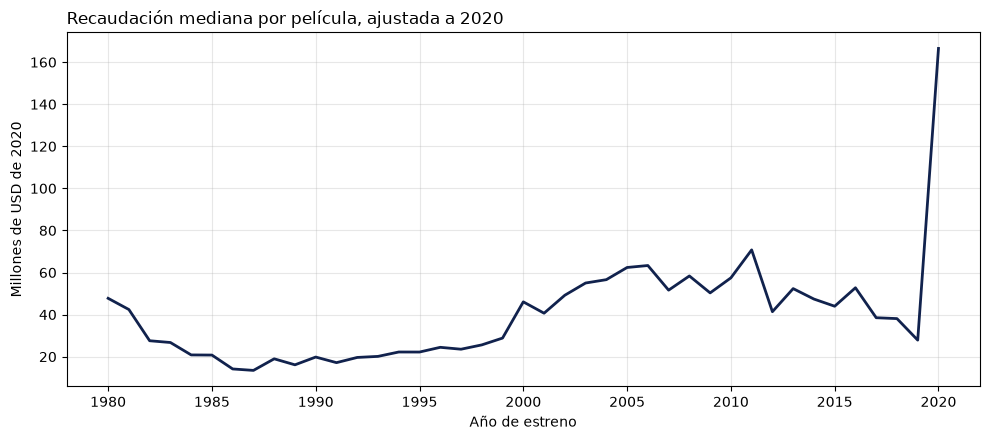

In [52]:
AZUL = "#11224D"
DORADO = "#D4AF37"

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(
    evolucion_anual["anio_estreno"],
    evolucion_anual["recaudacion_mediana_real"] / 1_000_000,
    color=AZUL, linewidth=2,
)
ax.set_title("Recaudación mediana por película, ajustada a 2020", loc="left")
ax.set_xlabel("Año de estreno")
ax.set_ylabel("Millones de USD de 2020")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Interpretación del gráfico:** la recaudación real de una película típica aumenta desde los años 80 hasta los 2000, aunque presenta variaciones importantes entre años. En la década de 2010 el nivel deja de crecer de forma sostenida. Para una decisión de inversión, esto sugiere que el crecimiento histórico del mercado no garantiza que una película individual recaude cada vez más. El valor de 2020 no se toma como tendencia porque se basa en solo 25 títulos.

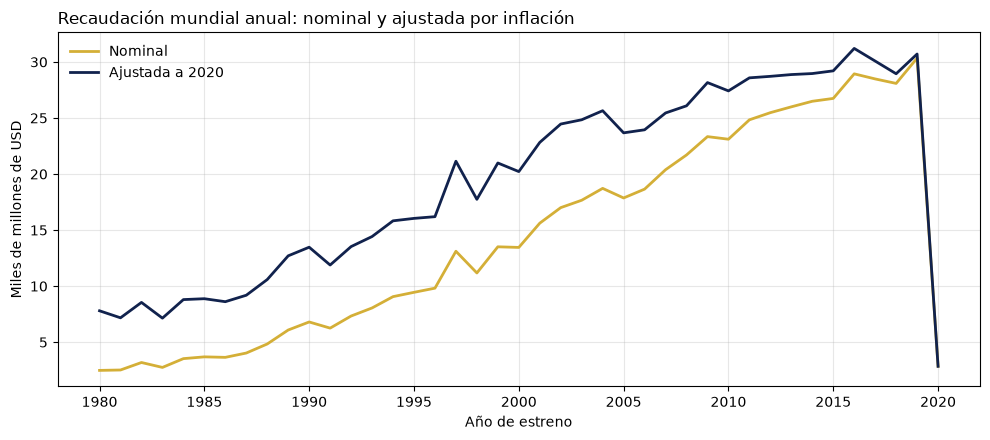

In [53]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(
    evolucion_anual["anio_estreno"],
    evolucion_anual["recaudacion_nominal_miles_millones"],
    color=DORADO, linewidth=2, label="Nominal",
)
ax.plot(
    evolucion_anual["anio_estreno"],
    evolucion_anual["recaudacion_real_miles_millones"],
    color=AZUL, linewidth=2, label="Ajustada a 2020",
)
ax.set_title("Recaudación mundial anual: nominal y ajustada por inflación", loc="left")
ax.set_xlabel("Año de estreno")
ax.set_ylabel("Miles de millones de USD")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Interpretación del gráfico:** en los años más antiguos la recaudación ajustada es muy superior a la nominal, porque un dólar de esa época tenía mayor poder de compra. Las dos líneas se acercan gradualmente y coinciden en 2020, el año base. Por lo tanto, comparar únicamente valores nominales exageraría el crecimiento de largo plazo; para evaluar la evolución económica y comparar oportunidades se debe utilizar la serie ajustada por inflación.

In [54]:
peliculas_limpias["periodo"] = pd.cut(
    peliculas_limpias["anio_estreno"],
    bins=[1979, 1989, 1999, 2009, 2020],
    labels=["1980-1989", "1990-1999", "2000-2009", "2010-2020"],
)

comparacion_periodos = (
    peliculas_limpias.groupby("periodo", observed=True)
    .agg(
        peliculas=("id_pelicula", "size"),
        recaudacion_mediana_2020=("recaudacion_2020_usd", "median"),
        recaudacion_total_2020=("recaudacion_2020_usd", "sum"),
    )
)
comparacion_periodos.round(0)

,peliculas,recaudacion_mediana_2020,recaudacion_total_2020
periodo,,,
1980-1989,1643,20915616.0,89444555440.0
1990-1999,2000,22131263.0,161253360349.0
2000-2009,2000,53422722.0,245310649755.0
2010-2020,2025,46292975.0,295547251188.0


**Conclusión:** la recaudación mediana ajustada por película pasó de aproximadamente USD 20,9 millones en los años 80 a USD 53,4 millones en los años 2000, y luego se moderó a USD 46,3 millones en 2010-2020. La diferencia entre la serie nominal y la real muestra que una parte del crecimiento observado se explica por la inflación.

**Precaución:** la base contiene una muestra histórica y no necesariamente todos los estrenos de cada año. Por eso, la cantidad y la recaudación total describen la cobertura de esta base; no deben interpretarse directamente como el tamaño completo del mercado mundial. Además, 2020 contiene solo 25 películas y parece ser un año parcial, por lo que no se usa aisladamente para concluir una tendencia.

## 3.2 Rentabilidad por género

Se comparan el ROI promedio, el ROI mediano y la proporción de películas que recuperaron la inversión. La mediana representa mejor una película típica, mientras que la diferencia entre promedio y mediana permite detectar géneros influidos por unos pocos éxitos extraordinarios.

In [55]:
rentabilidad_genero = (
    peliculas_financieras.groupby("genero")
    .agg(
        peliculas=("id_pelicula", "size"),
        roi_promedio=("roi", "mean"),
        roi_mediano=("roi", "median"),
        tasa_recuperacion=("recupero_inversion", "mean"),
        presupuesto_mediano_2020=("presupuesto_2020_usd", "median"),
    )
)

rentabilidad_genero.sort_values("roi_mediano", ascending=False).round(2)

,peliculas,roi_promedio,roi_mediano,tasa_recuperacion,presupuesto_mediano_2020
genero,,,,,
Familiar,4,20.13,3.45,0.5,31094325.62
Suspenso,7,3.3,2.7,0.57,14432446.13
Terror,254,75.86,2.08,0.58,12399638.37
Animación,273,3.0,1.92,0.58,82453205.89
Fantasía,42,1.52,1.14,0.43,16066341.67
Misterio,17,1.8,0.98,0.41,41236456.34
Aventura,323,4.68,0.88,0.39,46029346.38
Acción,1405,5.53,0.87,0.38,55770747.36
Comedia,1479,3.96,0.79,0.39,26397388.82


In [56]:
minimo_peliculas_genero = 30
generos_representativos = rentabilidad_genero.loc[
    rentabilidad_genero["peliculas"] >= minimo_peliculas_genero
].sort_values("roi_mediano", ascending=False)

print(f"Criterio mínimo: {minimo_peliculas_genero} películas con datos financieros")
print(f"Géneros incluidos en la comparación: {len(generos_representativos)}")
generos_representativos.round(2)

Criterio mínimo: 30 películas con datos financieros
Géneros incluidos en la comparación: 9


,peliculas,roi_promedio,roi_mediano,tasa_recuperacion,presupuesto_mediano_2020
genero,,,,,
Terror,254,75.86,2.08,0.58,12399638.37
Animación,273,3.0,1.92,0.58,82453205.89
Fantasía,42,1.52,1.14,0.43,16066341.67
Aventura,323,4.68,0.88,0.39,46029346.38
Acción,1405,5.53,0.87,0.38,55770747.36
Comedia,1479,3.96,0.79,0.39,26397388.82
Drama,862,2.74,0.53,0.37,24495816.74
Biografía,312,1.71,0.48,0.32,26958333.33
Policial,398,3.38,0.34,0.29,25859523.6


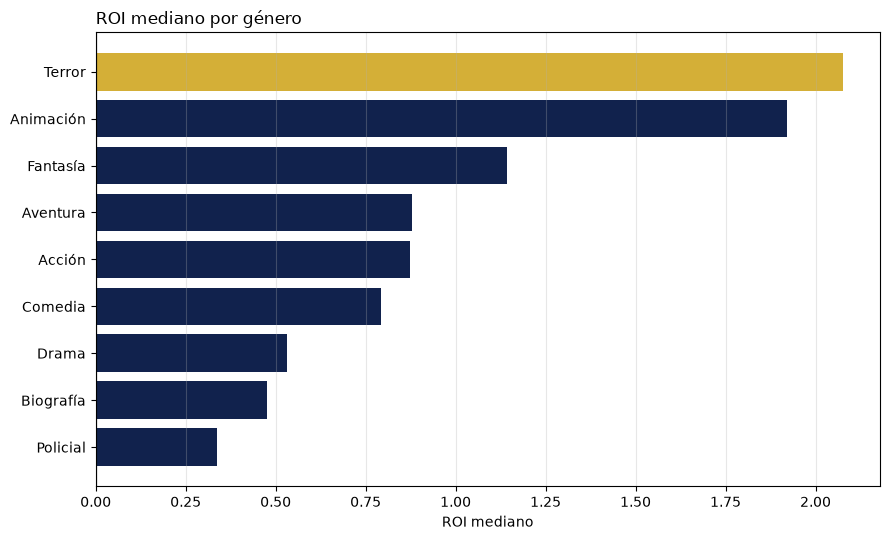

In [57]:
datos_grafico_genero = generos_representativos.sort_values("roi_mediano")
colores_genero = [
    DORADO if valor == datos_grafico_genero["roi_mediano"].max() else AZUL
    for valor in datos_grafico_genero["roi_mediano"]
]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(
    datos_grafico_genero.index,
    datos_grafico_genero["roi_mediano"],
    color=colores_genero,
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("ROI mediano por género", loc="left")
ax.set_xlabel("ROI mediano")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

**Interpretación del gráfico:** Terror presenta el mayor ROI mediano (2,08), seguido por Animación (1,92). Ambos recuperaron la inversión en aproximadamente el 58 % de los casos. Sin embargo, su escala es distinta: el presupuesto mediano ajustado es de USD 12,4 millones en Terror y USD 82,5 millones en Animación. Terror permite diversificar con menos capital, mientras que Animación exige apuestas mayores. Policial tiene el ROI mediano más bajo (0,34) y una tasa de recuperación de 29 %, por lo que históricamente ofrece la combinación menos atractiva entre los géneros representativos. El ROI promedio de Terror (75,86) no se usa como retorno esperado porque está dominado por pocos éxitos extremos.

## 3.3 Relación entre puntuación IMDb y retorno

Se analiza si una mejor evaluación del público está asociada con mayor rentabilidad. Como el ROI tiene valores extremos, además de calcular la correlación se agrupan las películas en rangos de puntuación y se comparan sus medianas y tasas de recuperación.

In [58]:
datos_imdb = peliculas_financieras.dropna(subset=["puntaje_imdb", "roi"]).copy()
correlacion_imdb_roi = datos_imdb["puntaje_imdb"].corr(datos_imdb["roi"])

print(f"Películas analizadas: {len(datos_imdb):,}")
print(f"Correlación entre puntuación IMDb y ROI: {correlacion_imdb_roi:.3f}")

Películas analizadas: 5,371
Correlación entre puntuación IMDb y ROI: 0.009


In [59]:
datos_imdb["rango_imdb"] = pd.cut(
    datos_imdb["puntaje_imdb"],
    bins=[0, 5, 6, 7, 8, 10],
    labels=["Hasta 5", "5 a 6", "6 a 7", "7 a 8", "Más de 8"],
)

retorno_por_imdb = (
    datos_imdb.groupby("rango_imdb", observed=True)
    .agg(
        peliculas=("id_pelicula", "size"),
        roi_promedio=("roi", "mean"),
        roi_mediano=("roi", "median"),
        tasa_recuperacion=("recupero_inversion", "mean"),
    )
)
retorno_por_imdb.round(2)

,peliculas,roi_promedio,roi_mediano,tasa_recuperacion
rango_imdb,,,,
Hasta 5,418,2.8,0.01,0.26
5 a 6,1312,1.93,0.39,0.29
6 a 7,2294,11.38,0.78,0.37
7 a 8,1212,7.36,1.82,0.54
Más de 8,135,6.71,4.04,0.79


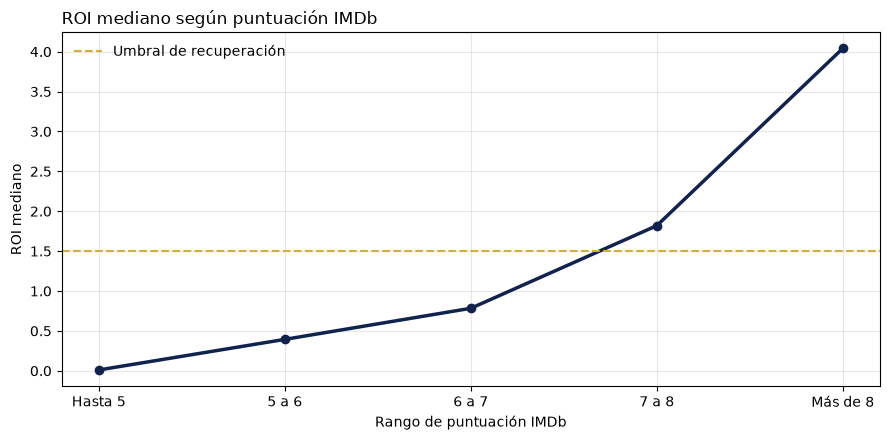

In [60]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(
    retorno_por_imdb.index.astype(str),
    retorno_por_imdb["roi_mediano"],
    color=AZUL, linewidth=2.5, marker="o",
)
ax.axhline(1.5, color=DORADO, linestyle="--", label="Umbral de recuperación")
ax.set_title("ROI mediano según puntuación IMDb", loc="left")
ax.set_xlabel("Rango de puntuación IMDb")
ax.set_ylabel("ROI mediano")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Interpretación del gráfico:** el ROI mediano aumenta de forma clara con la puntuación. Las películas con IMDb de hasta 5 presentan un ROI mediano de 0,01 y recuperan la inversión en 26 % de los casos; las que superan 8 alcanzan un ROI mediano de 4,04 y una recuperación de 79 %. La correlación lineal simple es apenas 0,009 porque los éxitos extremos distorsionan el ROI promedio. Por eso, los rangos y las medianas muestran mejor la relación. Para el fondo, una buena recepción del público aparece asociada con menor riesgo, aunque IMDb se conoce después del estreno y no puede utilizarse por sí sola para seleccionar proyectos futuros.

## 3.4 Probabilidad de pérdida y peor 10 %

Se considera pérdida de capital cuando una película no supera 2,5 veces su presupuesto, de acuerdo con el criterio de recuperación de la consigna. Además, el percentil 10 del ROI muestra el resultado máximo que obtiene el 10 % de peor desempeño: cuanto más negativo sea, mayor es el riesgo en un escenario adverso.

In [61]:
probabilidad_perdida_general = 1 - peliculas_financieras["recupero_inversion"].mean()
corte_peor_10_general = peliculas_financieras["roi"].quantile(0.10)
peor_10_general = peliculas_financieras.loc[
    peliculas_financieras["roi"] <= corte_peor_10_general
]

print(f"Probabilidad histórica de no recuperar la inversión: {probabilidad_perdida_general:.2%}")
print(f"Corte que define al peor 10 % del ROI: {corte_peor_10_general:.2f}")
print(f"ROI mediano dentro del peor 10 %: {peor_10_general['roi'].median():.2f}")
print(f"Cantidad de películas en el peor 10 %: {len(peor_10_general):,}")

Probabilidad histórica de no recuperar la inversión: 60.99%
Corte que define al peor 10 % del ROI: -0.73
ROI mediano dentro del peor 10 %: -0.87
Cantidad de películas en el peor 10 %: 539


In [62]:
riesgo_genero = (
    peliculas_financieras.groupby("genero")
    .agg(
        peliculas=("id_pelicula", "size"),
        roi_mediano=("roi", "median"),
        roi_peor_10=("roi", lambda serie: serie.quantile(0.10)),
        tasa_recuperacion=("recupero_inversion", "mean"),
    )
)
riesgo_genero["probabilidad_perdida"] = 1 - riesgo_genero["tasa_recuperacion"]
riesgo_genero_representativo = riesgo_genero.loc[
    riesgo_genero["peliculas"] >= minimo_peliculas_genero
].sort_values("probabilidad_perdida")

riesgo_genero_representativo.round(2)

,peliculas,roi_mediano,roi_peor_10,tasa_recuperacion,probabilidad_perdida
genero,,,,,
Animación,273,1.92,-0.38,0.58,0.42
Terror,254,2.08,-0.57,0.58,0.42
Fantasía,42,1.14,-0.72,0.43,0.57
Aventura,323,0.88,-0.78,0.39,0.61
Comedia,1479,0.79,-0.72,0.39,0.61
Acción,1405,0.87,-0.61,0.38,0.62
Drama,862,0.53,-0.84,0.37,0.63
Biografía,312,0.48,-0.76,0.32,0.68
Policial,398,0.34,-0.83,0.29,0.71


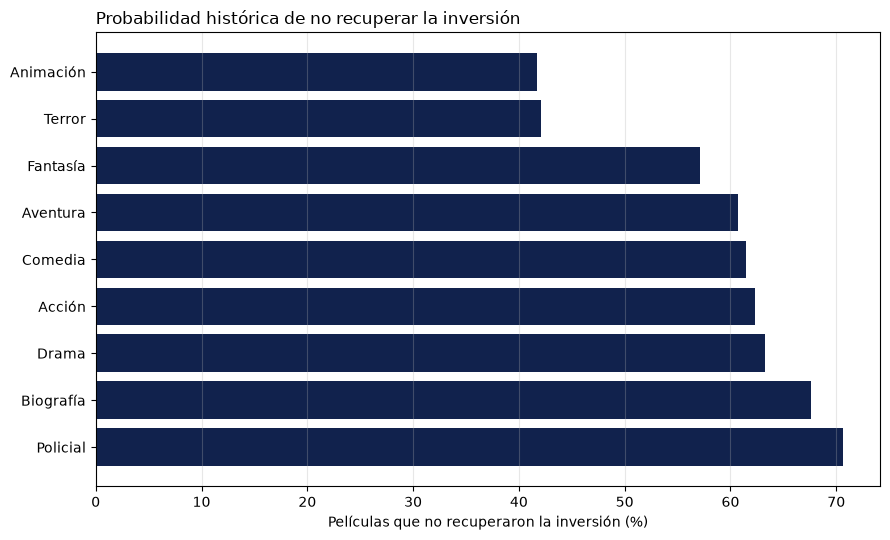

In [63]:
datos_grafico_riesgo = riesgo_genero_representativo.sort_values("probabilidad_perdida", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(
    datos_grafico_riesgo.index,
    datos_grafico_riesgo["probabilidad_perdida"] * 100,
    color=AZUL,
)
ax.set_title("Probabilidad histórica de no recuperar la inversión", loc="left")
ax.set_xlabel("Películas que no recuperaron la inversión (%)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

**Interpretación del gráfico:** el 60,99 % de todas las películas no alcanzó el umbral de recuperación. Animación y Terror presentan el menor riesgo entre los géneros representativos, pero aun así aproximadamente 42 % de sus películas no recuperó la inversión. Policial alcanza el mayor riesgo, con 71 %, seguido por Biografía con 68 %. En el peor 10 %, Animación tiene el resultado menos negativo (ROI de -0,38), mientras que Drama (-0,84) y Policial (-0,83) muestran pérdidas más profundas. Esto indica que Terror ofrece más retorno mediano, pero Animación protege mejor el capital en escenarios adversos; ninguna categoría elimina por completo el riesgo.

## 3.5 Segmentos con mejor combinación de riesgo y retorno

El género por sí solo puede ocultar diferencias importantes de escala. Por eso se combina con cuatro niveles de presupuesto ajustado: bajo, medio, alto y muy alto. Solo se consideran segmentos con al menos 30 películas para que la comparación tenga una base histórica razonable.

In [64]:
peliculas_financieras["nivel_presupuesto"] = pd.cut(
    peliculas_financieras["presupuesto_2020_usd"],
    bins=[0, 20_000_000, 50_000_000, 100_000_000, float("inf")],
    labels=["Bajo: hasta 20 M", "Medio: 20 a 50 M", "Alto: 50 a 100 M", "Muy alto: más de 100 M"],
)

print(peliculas_financieras["nivel_presupuesto"].value_counts(sort=False))

nivel_presupuesto
Bajo: hasta 20 M          1708
Medio: 20 a 50 M          1921
Alto: 50 a 100 M          1063
Muy alto: más de 100 M     697
Name: count, dtype: int64


In [65]:
segmentos = (
    peliculas_financieras.groupby(
        ["genero", "nivel_presupuesto"], observed=True
    )
    .agg(
        peliculas=("id_pelicula", "size"),
        presupuesto_mediano=("presupuesto_2020_usd", "median"),
        roi_mediano=("roi", "median"),
        roi_peor_10=("roi", lambda serie: serie.quantile(0.10)),
        tasa_recuperacion=("recupero_inversion", "mean"),
    )
    .reset_index()
)
segmentos["probabilidad_perdida"] = 1 - segmentos["tasa_recuperacion"]

segmentos_representativos = segmentos.loc[segmentos["peliculas"] >= 30].copy()
print(f"Segmentos totales: {len(segmentos)}")
print(f"Segmentos con al menos 30 películas: {len(segmentos_representativos)}")

Segmentos totales: 52
Segmentos con al menos 30 películas: 27


In [66]:
roi_mediano_general = peliculas_financieras["roi"].median()
tasa_recuperacion_general = peliculas_financieras["recupero_inversion"].mean()

segmentos_atractivos = segmentos_representativos.loc[
    (segmentos_representativos["roi_mediano"] > roi_mediano_general)
    & (segmentos_representativos["tasa_recuperacion"] > tasa_recuperacion_general)
].sort_values(
    ["tasa_recuperacion", "roi_mediano"], ascending=False
)

segmentos_atractivos[[
    "genero", "nivel_presupuesto", "peliculas",
    "presupuesto_mediano", "roi_mediano", "roi_peor_10",
    "tasa_recuperacion", "probabilidad_perdida",
]].round(2)

,genero,nivel_presupuesto,peliculas,presupuesto_mediano,roi_mediano,roi_peor_10,tasa_recuperacion,probabilidad_perdida
46,Terror,Bajo: hasta 20 M,163,6597833.01,3.09,-0.62,0.66,0.34
6,Animación,Alto: 50 a 100 M,74,77862061.47,2.39,-0.19,0.62,0.38
7,Animación,Muy alto: más de 100 M,112,155349044.02,1.87,-0.12,0.59,0.41
5,Animación,Medio: 20 a 50 M,62,36018851.13,1.81,-0.52,0.55,0.45
8,Aventura,Bajo: hasta 20 M,74,12529802.43,1.55,-0.73,0.51,0.49
3,Acción,Muy alto: más de 100 M,382,150331477.37,1.5,-0.13,0.5,0.5
47,Terror,Medio: 20 a 50 M,72,26150202.0,1.4,-0.57,0.49,0.51
11,Aventura,Muy alto: más de 100 M,66,143849703.07,1.34,-0.07,0.48,0.52
19,Comedia,Bajo: hasta 20 M,555,10269841.27,1.07,-0.83,0.43,0.57
23,Drama,Bajo: hasta 20 M,371,9492893.17,0.99,-0.89,0.43,0.57


**Conclusión:** Terror de bajo presupuesto ofrece el mayor ROI mediano (3,09) y la mayor tasa de recuperación (66 %), aunque en su peor 10 % el ROI cae a -0,62. Animación de presupuesto alto y muy alto combina recuperación de 62 % y 59 % con pérdidas menos profundas en el peor 10 % (-0,19 y -0,12), pero requiere mucho más capital por proyecto. Acción y Aventura de presupuesto muy alto tienen retornos medianos más moderados y tasas de recuperación cercanas al 50 %, aunque muestran una defensa relativamente buena en escenarios adversos. Estos perfiles son complementarios: Terror aporta potencial y diversificación por bajo costo, mientras que Animación y las grandes producciones aportan mayor protección del capital por proyecto. Esta comparación servirá como base para construir el portafolio, sin asumir que un único segmento domina en todas las métricas.

## Etapa 4. Visualización para la toma de decisiones

Los gráficos anteriores respondieron preguntas específicas sobre evolución, retorno, puntuación y riesgo. A continuación se agrega una visualización interactiva con Plotly para comparar conjuntamente los segmentos que podrían formar parte del portafolio.

## 4.1 Mapa interactivo de riesgo y retorno

En el gráfico, moverse hacia arriba significa mayor ROI mediano y moverse hacia la izquierda significa menor probabilidad de pérdida. El tamaño de la burbuja representa la cantidad de películas históricas del segmento. Al pasar el cursor se observan el género, el nivel de presupuesto y el resultado del peor 10 %.

In [67]:
datos_interactivos = segmentos_representativos.copy()
datos_interactivos["probabilidad_perdida_pct"] = (
    datos_interactivos["probabilidad_perdida"] * 100
)
datos_interactivos["segmento"] = (
    datos_interactivos["genero"].astype(str)
    + " | "
    + datos_interactivos["nivel_presupuesto"].astype(str)
)

In [68]:
figura = px.scatter(
    datos_interactivos,
    x="probabilidad_perdida_pct",
    y="roi_mediano",
    size="peliculas",
    color="nivel_presupuesto",
    hover_name="segmento",
    hover_data={
        "peliculas": True,
        "roi_peor_10": ".2f",
        "presupuesto_mediano": ":,.0f",
        "probabilidad_perdida_pct": ".1f",
        "nivel_presupuesto": False,
    },
    labels={
        "probabilidad_perdida_pct": "Probabilidad de no recuperar (%)",
        "roi_mediano": "ROI mediano",
        "nivel_presupuesto": "Nivel de presupuesto",
        "roi_peor_10": "ROI del peor 10 %",
        "presupuesto_mediano": "Presupuesto mediano (USD 2020)",
    },
    title="Segmentos cinematográficos: riesgo y retorno histórico",
)
figura.add_vline(
    x=probabilidad_perdida_general * 100,
    line_dash="dash", line_color="gray",
)
figura.add_hline(
    y=roi_mediano_general,
    line_dash="dash", line_color="gray",
)
figura.update_layout(template="plotly_white")
figura.show()
figura.write_html(
    "../salidas/riesgo_retorno_segmentos.html", include_plotlyjs="cdn"
)

**Interpretación del gráfico:** el cuadrante superior izquierdo reúne segmentos con retorno mediano superior al general y menor probabilidad de pérdida. Terror de bajo presupuesto ocupa la posición más atractiva por retorno y recuperación, aunque su peor 10 % sigue mostrando riesgo considerable. Los segmentos de Animación con presupuestos altos aparecen más cerca del extremo de menor riesgo y tienen pérdidas menos profundas, pero consumen mucho más capital por proyecto. Las burbujas grandes de Comedia, Drama y Acción muestran resultados respaldados por más observaciones, aunque varios de esos segmentos quedan por debajo del retorno deseado o por encima del riesgo general. La decisión del portafolio debe combinar posiciones distintas del gráfico en lugar de concentrarse en una sola burbuja.

**Conclusión de la etapa:** se cuenta con gráficos estáticos para explicar tendencias concretas y un gráfico interactivo para explorar la relación entre riesgo, retorno, escala y cantidad de observaciones. Cada visualización incluye una interpretación y una advertencia cuando la cobertura limita la conclusión.

## Etapa 5. Tesis de inversión

Arroyo Capital dispone de USD 500 millones para invertir durante tres años. La propuesta combina segmentos con perfiles diferentes para evitar que el resultado dependa de un solo género o de una única escala de producción.

## 5.1 Distribución propuesta

La asignación prioriza Terror de bajo presupuesto por su retorno mediano y Animación de presupuesto alto por su mejor protección histórica. Acción de presupuesto muy alto y Aventura de bajo presupuesto aportan diversificación. Los montos por proyecto respetan los rangos utilizados en el análisis.

In [69]:
plan_portafolio = pd.DataFrame({
    "genero": ["Terror", "Animación", "Acción", "Aventura"],
    "nivel_presupuesto": [
        "Bajo: hasta 20 M",
        "Alto: 50 a 100 M",
        "Muy alto: más de 100 M",
        "Bajo: hasta 20 M",
    ],
    "asignacion_usd": [120_000_000, 160_000_000, 110_000_000, 110_000_000],
    "cantidad_proyectos": [12, 2, 1, 6],
})
plan_portafolio["inversion_por_proyecto_usd"] = (
    plan_portafolio["asignacion_usd"] / plan_portafolio["cantidad_proyectos"]
)
plan_portafolio["participacion"] = plan_portafolio["asignacion_usd"] / 500_000_000
plan_portafolio

,genero,nivel_presupuesto,asignacion_usd,cantidad_proyectos,inversion_por_proyecto_usd,participacion
0,Terror,Bajo: hasta 20 M,120000000,12,1.000000e+07,0.24
1,Animación,Alto: 50 a 100 M,160000000,2,8.000000e+07,0.32
2,Acción,Muy alto: más de 100 M,110000000,1,1.100000e+08,0.22
3,Aventura,Bajo: hasta 20 M,110000000,6,1.833333e+07,0.22


In [70]:
capital_total = 500_000_000
proyectos_totales = int(plan_portafolio["cantidad_proyectos"].sum())

assert plan_portafolio["asignacion_usd"].sum() == capital_total
assert proyectos_totales == 21

print(f"Capital asignado: USD {plan_portafolio['asignacion_usd'].sum():,.0f}")
print(f"Cantidad total de proyectos: {proyectos_totales}")
print("Promedio aproximado: 7 proyectos por año durante tres años")

Capital asignado: USD 500,000,000
Cantidad total de proyectos: 21
Promedio aproximado: 7 proyectos por año durante tres años


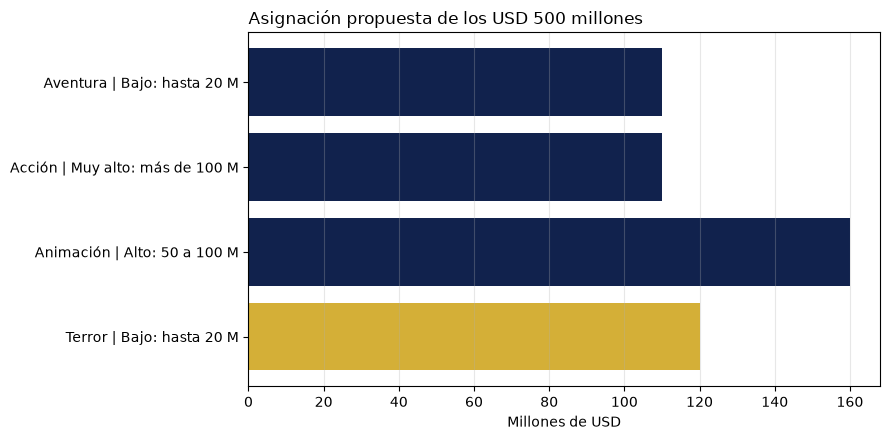

In [71]:
etiquetas_portafolio = (
    plan_portafolio["genero"] + " | " + plan_portafolio["nivel_presupuesto"]
)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(
    etiquetas_portafolio,
    plan_portafolio["asignacion_usd"] / 1_000_000,
    color=[DORADO, AZUL, AZUL, AZUL],
)
ax.set_title("Asignación propuesta de los USD 500 millones", loc="left")
ax.set_xlabel("Millones de USD")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

**Interpretación del gráfico:** Animación recibe la mayor asignación, USD 160 millones, pero se divide en dos proyectos para reducir la exposición a una única película. Terror recibe USD 120 millones distribuidos entre 12 producciones, lo que aprovecha su bajo costo y diversifica el riesgo. Acción concentra USD 110 millones en una producción de gran escala, mientras que Aventura distribuye otros USD 110 millones entre seis proyectos pequeños. Ningún segmento concentra más del 32 % del capital.

## 5.2 Simulación del portafolio

La simulación toma al azar, con reemplazo, resultados históricos del mismo género y nivel de presupuesto para cada proyecto. Se realizan 10.000 escenarios. Para estimar cuánto capital vuelve al fondo se divide la recaudación entre 2,5, manteniendo el criterio de recuperación indicado en la consigna. Para no proyectar como repetibles los éxitos más extraordinarios, el múltiplo de recaudación se limita al percentil 90 de cada segmento. Esta decisión hace que la estimación sea más prudente.

In [72]:
generador = np.random.default_rng(2026)
cantidad_simulaciones = 10_000
capital_recuperado_simulado = np.zeros(cantidad_simulaciones)
limites_extremos = []

for _, grupo in plan_portafolio.iterrows():
    resultados_historicos = peliculas_financieras.loc[
        (peliculas_financieras["genero"] == grupo["genero"])
        & (peliculas_financieras["nivel_presupuesto"] == grupo["nivel_presupuesto"]),
        "multiplo_recaudacion",
    ].dropna()

    limite_percentil_90 = resultados_historicos.quantile(0.90)
    resultados_prudentes = resultados_historicos.clip(upper=limite_percentil_90)
    limites_extremos.append([grupo["genero"], limite_percentil_90])

    resultados_sorteados = generador.choice(
        resultados_prudentes,
        size=(cantidad_simulaciones, int(grupo["cantidad_proyectos"])),
        replace=True,
    )
    capital_recuperado_simulado += (
        grupo["inversion_por_proyecto_usd"]
        * resultados_sorteados / 2.5
    ).sum(axis=1)

retornos_portafolio = pd.Series(
    capital_recuperado_simulado / capital_total - 1,
    name="retorno_portafolio",
)
pd.DataFrame(limites_extremos, columns=["genero", "multiplo_maximo_simulado"]).round(2)

,genero,multiplo_maximo_simulado
0,Terror,30.93
1,Animación,8.36
2,Acción,5.54
3,Aventura,10.42


In [73]:
retorno_esperado_mediano = retornos_portafolio.median()
probabilidad_perder_capital = (retornos_portafolio < 0).mean()
retorno_percentil_10 = retornos_portafolio.quantile(0.10)
retorno_percentil_90 = retornos_portafolio.quantile(0.90)
capital_final_mediano = capital_total * (1 + retorno_esperado_mediano)

print(f"Retorno mediano esperado del portafolio: {retorno_esperado_mediano:.2%}")
print(f"Capital final mediano: USD {capital_final_mediano:,.0f}")
print(f"Probabilidad de perder capital: {probabilidad_perder_capital:.2%}")
print(f"Retorno en el percentil 10: {retorno_percentil_10:.2%}")
print(f"Retorno en el percentil 90: {retorno_percentil_90:.2%}")

Retorno mediano esperado del portafolio: 92.97%
Capital final mediano: USD 964,863,276
Probabilidad de perder capital: 0.71%
Retorno en el percentil 10: 41.11%
Retorno en el percentil 90: 146.82%


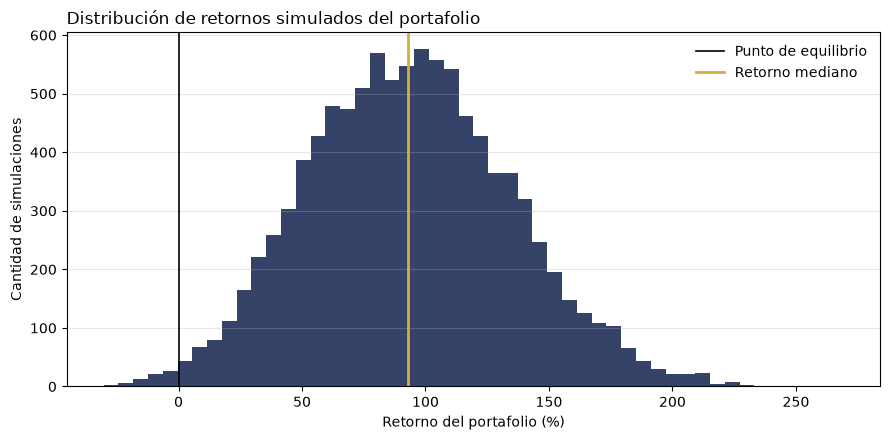

In [74]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(retornos_portafolio * 100, bins=50, color=AZUL, alpha=0.85)
ax.axvline(0, color="black", linewidth=1.2, label="Punto de equilibrio")
ax.axvline(
    retorno_esperado_mediano * 100,
    color=DORADO, linewidth=2, label="Retorno mediano",
)
ax.set_title("Distribución de retornos simulados del portafolio", loc="left")
ax.set_xlabel("Retorno del portafolio (%)")
ax.set_ylabel("Cantidad de simulaciones")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

**Interpretación del gráfico:** la mayoría de los 10.000 escenarios queda a la derecha del punto de equilibrio. El retorno mediano estimado es 92,97 % para el portafolio completo durante los tres años, equivalente a un capital final mediano de aproximadamente USD 965 millones. La probabilidad simulada de terminar por debajo de los USD 500 millones iniciales es 0,71 %. En un escenario desfavorable de percentil 10, el retorno todavía es 41,11 %, mientras que el percentil 90 alcanza 146,82 %. La distribución tiene una cola hacia la derecha porque algunos éxitos generan múltiplos altos, incluso después de limitar el 10 % más extremo. Estos valores son resultados de una simulación histórica, no una garantía: se supone que los proyectos son independientes y no se modelan cambios de mercado, demoras, costos financieros ni shocks que afecten simultáneamente a todas las producciones.

## 5.3 Inversiones que se evitarían

Se evitaría concentrar capital en películas policiales: entre los géneros representativos tienen el ROI mediano más bajo (0,34), la mayor probabilidad de no recuperar la inversión (71 %) y un ROI de -0,83 en el peor 10 %. También se evitarían segmentos con menos de 30 observaciones, aunque presenten retornos altos, porque la evidencia histórica no alcanza para sostener una decisión de USD 500 millones. Finalmente, no se financiaría todo el portafolio con una única superproducción o un solo género, ya que el resultado dependería demasiado de un estreno.

## 5.4 Conclusión de inversión

Se propone financiar 21 películas durante tres años: 12 de Terror de bajo presupuesto, 2 de Animación de presupuesto alto, 1 de Acción de presupuesto muy alto y 6 de Aventura de bajo presupuesto. La distribución utiliza los USD 500 millones completos y combina proyectos pequeños, que permiten diversificar, con producciones grandes que históricamente presentan pérdidas menos profundas. La simulación respalda la tesis, pero la decisión final debe mantenerse diversificada y revisar cada proyecto individualmente; el desempeño histórico del segmento no reemplaza el análisis del guion, el equipo, la distribución y el plan comercial.